In [5]:
!pip install -q ultralytics==8.4.216 "numpy>=2.0"

from ultralytics.utils.downloads import download
from pathlib import Path

# Скачиваем и распаковываем датасет African Wildlife
dataset_dir = Path("datasets/african-wildlife")
download("https://github.com/ultralytics/assets/releases/download/v0.0.0/african-wildlife.zip", dir=dataset_dir)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.5 which is incompatible.
WARNING ⚠️ Skipping datasets/african-wildlife/african-wildlife.zip unzip as destination directory /content/datasets/african-wildlife/african-wildlife is not empty.


Классы: {0: 'buffalo', 1: 'elephant', 2: 'rhino', 3: 'zebra'}
TRAIN: 1052 картинок, 1931 объектов (пустых файлов разметки: 0)
VAL: 225 картинок, 379 объектов (пустых файлов разметки: 0)
TEST: 227 картинок, 375 объектов (пустых файлов разметки: 0)


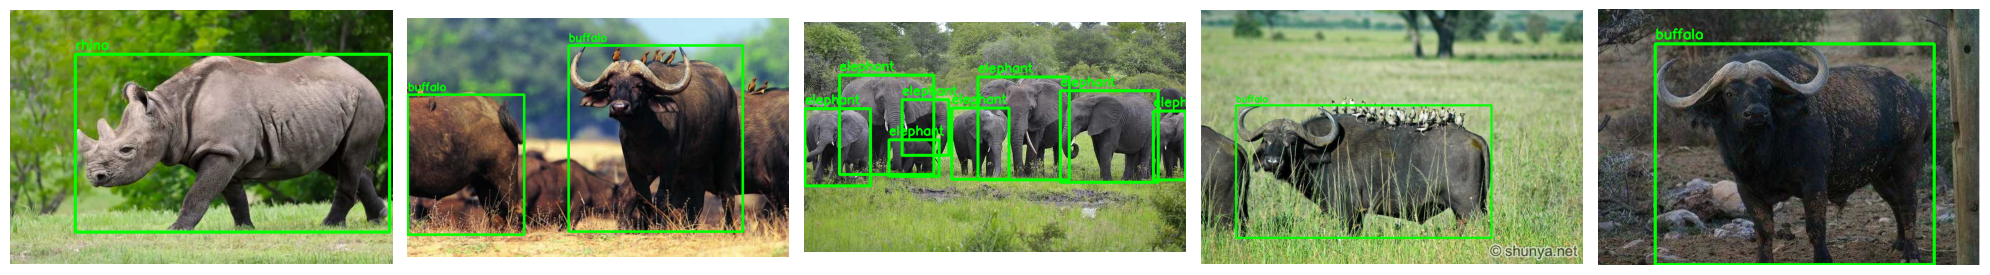

In [1]:
import yaml
import random
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

base = Path("datasets/african-wildlife/african-wildlife")

# Создаем конфиг data.yaml
data_cfg = {
    "path": str(base.resolve()),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {0: "buffalo", 1: "elephant", 2: "rhino", 3: "zebra"}
}
with open("data.yaml", "w") as f:
    yaml.dump(data_cfg, f, sort_keys=False)

class_names = data_cfg["names"]
print("Классы:", class_names)

# Считаем картинки и объекты по сплитам
for split in ["train", "val", "test"]:
    imgs = list((base / "images" / split).glob("*.*"))
    lbls = list((base / "labels" / split).glob("*.txt"))
    total_boxes = 0
    empty_lbls = 0
    for lbl in lbls:
        lines = [line.strip() for line in lbl.read_text().splitlines() if line.strip()]
        if not lines:
            empty_lbls += 1
        total_boxes += len(lines)
    print(f"{split.upper()}: {len(imgs)} картинок, {total_boxes} объектов (пустых файлов разметки: {empty_lbls})")

# Показываем 5 случайных картинок с истинными рамками (Ground Truth)
random.seed(42)
train_imgs = list((base / "images" / "train").glob("*.*"))
sample_imgs = random.sample(train_imgs, 5)

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, img_path in zip(axes, sample_imgs):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape
    lbl_path = base / "labels" / "train" / f"{img_path.stem}.txt"
    if lbl_path.exists():
        for line in lbl_path.read_text().splitlines():
            cls_id, xc, yc, bw, bh = map(float, line.split())
            x1 = int((xc - bw / 2) * w)
            y1 = int((yc - bh / 2) * h)
            x2 = int((xc + bw / 2) * w)
            y2 = int((yc + bh / 2) * h)
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
            cv2.putText(img, class_names[int(cls_id)], (x1, max(y1 - 8, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
    ax.imshow(img)
    ax.axis("off")
plt.tight_layout()
plt.savefig("ground_truth_samples.png", dpi=150)
plt.show()

In [2]:
import time
from ultralytics import YOLO

# Загружаем предобученную легкую модель YOLOv8n
baseline_model = YOLO("yolov8n.pt")

start_time = time.time()

# Обучаем базовую модель (10 эпох, размер картинки 256x256)
baseline_results = baseline_model.train(
    data="data.yaml",
    epochs=10,
    imgsz=256,
    batch=16,
    lr0=0.01,
    seed=42,
    deterministic=True,
    project="runs/detect",
    name="baseline_256"
)

baseline_time = time.time() - start_time
print(f"\nВремя обучения Baseline: {baseline_time:.1f} сек ({baseline_time/60:.2f} мин)")

# Оцениваем лучший чекпоинт (best.pt) на валидации (VAL)
best_baseline = YOLO("runs/detect/baseline_256/weights/best.pt")
val_base = best_baseline.val(data="data.yaml", split="val", imgsz=256)

print("\n=== РЕЗУЛЬТАТЫ BASELINE НА ВАЛИДАЦИИ ===")
print(f"Precision (P): {val_base.box.mp:.4f}")
print(f"Recall (R):    {val_base.box.mr:.4f}")
print(f"mAP@0.50:      {val_base.box.map50:.4f}")

WARNING ⚠️ Ultralytics settings updated to the latest schema. Existing values were preserved where possible. 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipu

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: You chose "Don't visualize my results"
wandb: Using W&B in offline mode.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


TensorBoard: model graph visualization added ✅
Using 1052 train, 225 val images for fraction=1.0 at imgsz=256
Using 0 dataloader workers
Logging results to /content/runs/detect/runs/detect/baseline_256
Starting training for 10 epochs...
Closing dataloader mosaic
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1022: UserWarning: The input to trace is already a ScriptModule, tracing it is a no-op. Returning the object as is.
  traced_func = _trace_impl(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/10         0G     0.9596      1.631      1.101         21        256: 100% ━━━━━━━━━━━━ 66/66 2.3s/it 2:35
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.3s/it 10.7s
                   all        225        379       0.64      0.652      0.696      0.475

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/10         0G     0.9876      1.217      1.117         26        256: 100% ━━━━━━━━━━━━ 66/66 2.3s/it 2:32
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.4s/it 11.1s
                   all        225        379      0.659      0.692      0.675      0.474

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/10         0G      1.003      1.181      1.122         23        256: 100% ━━━━━━━━━━━━ 66/6

epoch,▁▂▂▃▄▅▅▆▇▇█▇
lr/pg0,▃▆█▇▆▅▄▃▂▁
lr/pg1,▃▆█▇▆▅▄▃▂▁
lr/pg2,▃▆█▇▆▅▄▃▂▁
metrics/mAP50(B),▃▂▁▆▃▆▇▇███
metrics/mAP50-95(B),▃▃▁▅▄▆▇▇███
metrics/precision(B),▁▁▃▆▃▇▆█▇██
metrics/recall(B),▃▄▁▄▂▃▇▇███
model/GFLOPs,▁
model/parameters,▁
+7,...



Время обучения Baseline: 1739.5 сек (28.99 мин)


FileNotFoundError: [Errno 2] No such file or directory: 'runs/detect/baseline_256/weights/best.pt'

In [ ]:
import os
import time
from pathlib import Path
from ultralytics import YOLO

# Отключаем интерактивный запрос wandb, чтобы ячейка не ставилась на паузу
os.environ["WANDB_DISABLED"] = "true"

# Загружаем те же самые начальные предобученные веса yolov8n.pt
exp_model = YOLO("yolov8n.pt")

start_time = time.time()

# Контролируемый эксперимент: меняем ТОЛЬКО imgsz (256 -> 384)
exp_results = exp_model.train(
    data="data.yaml",
    epochs=10,
    imgsz=384,
    batch=16,
    lr0=0.01,
    seed=42,
    deterministic=True,
    project="runs_exp",
    name="exp_imgsz384"
)

exp_time = time.time() - start_time
print(f"\nВремя обучения Experiment (imgsz=384): {exp_time:.1f} сек ({exp_time/60:.2f} мин)")

# Находим сохраненный best.pt и оцениваем на валидации (VAL)
exp_best_path = Path(exp_results.save_dir) / "weights" / "best.pt"
print("Путь к лучшим весам эксперимента:", exp_best_path)

best_exp = YOLO(str(exp_best_path))
val_exp = best_exp.val(data="data.yaml", split="val", imgsz=384)

print("\n=== РЕЗУЛЬТАТЫ EXPERIMENT (imgsz=384) НА ВАЛИДАЦИИ ===")
print(f"Precision (P): {val_exp.box.mp:.4f}")
print(f"Recall (R):    {val_exp.box.mr:.4f}")
print(f"mAP@0.50:      {val_exp.box.map50:.4f}")

Ultralytics 8.4.216 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=384, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=exp_imgsz384, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, ov

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


TensorBoard: model graph visualization added ✅
Using 1052 train, 225 val images for fraction=1.0 at imgsz=384
Using 0 dataloader workers
Logging results to /content/runs/detect/runs_exp/exp_imgsz384
Starting training for 10 epochs...
Closing dataloader mosaic
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1022: UserWarning: The input to trace is already a ScriptModule, tracing it is a no-op. Returning the object as is.
  traced_func = _trace_impl(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/10         0G     0.8276      1.392       1.07         21        384: 100% ━━━━━━━━━━━━ 66/66 5.0s/it 5:30
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.7s/it 21.5s
                   all        225        379      0.858      0.744      0.831      0.626

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/10         0G     0.8938      1.119      1.102         26        384: 100% ━━━━━━━━━━━━ 66/66 4.9s/it 5:25
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.5s/it 19.6s
                   all        225        379      0.721      0.607       0.72      0.514

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/10         0G     0.9738       1.13      1.156         23        384: 100% ━━━━━━━━━━━━ 66/6

In [4]:
import pandas as pd
from ultralytics import YOLO

# Читаем сохраненный лог эксперимента из папки runs_exp/exp_imgsz384
exp_dir = "/content/runs/detect/runs_exp/exp_imgsz384"
df = pd.read_csv(f"{exp_dir}/results.csv")
df.columns = [c.strip() for c in df.columns]

total_time = df["time"].iloc[-1]
print(f"Время обучения Experiment (imgsz=384): {total_time:.1f} сек ({total_time/60:.2f} мин)")

# Проверяем лучший чекпоинт (best.pt) на валидации (VAL)
best_exp = YOLO(f"{exp_dir}/weights/best.pt")
val_exp = best_exp.val(data="data.yaml", split="val", imgsz=384)

print("\n=== РЕЗУЛЬТАТЫ EXPERIMENT (imgsz=384) НА ВАЛИДАЦИИ ===")
print(f"Precision (P): {val_exp.box.mp:.4f}")
print(f"Recall (R):    {val_exp.box.mr:.4f}")
print(f"mAP@0.50:      {val_exp.box.map50:.4f}")

Время обучения Experiment (imgsz=384): 3458.3 сек (57.64 мин)
Ultralytics 8.4.216 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 938.1±610.1 MB/s, size: 43.0 KB)
val: Scanning /content/datasets/african-wildlife/african-wildlife/labels/val.cache... 225 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 225/225 6.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 1.6s/it 24.2s
                   all        225        379      0.917      0.868      0.935      0.756
               buffalo         62         89      0.975      0.872      0.954      0.798
              elephant         53         91      0.835      0.824      0.906      0.723
                 rhino         55         85      0.932      0.918      0.945      0.778
                 zebra         59        1

Ultralytics 8.4.216 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 497.4±616.9 MB/s, size: 118.7 KB)
val: Scanning /content/datasets/african-wildlife/african-wildlife/labels/test... 227 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 227/227 310.3it/s 0.7s
val: New cache created: /content/datasets/african-wildlife/african-wildlife/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 1.2s/it 17.5s
                   all        227        375      0.957      0.902      0.917      0.747
               buffalo         49         66      0.969      0.937      0.952      0.808
              elephant         58         99      0.931      0.909      0.914      0.706
                 rhino         55         75      0.986      0.911      0.934      0.818
             

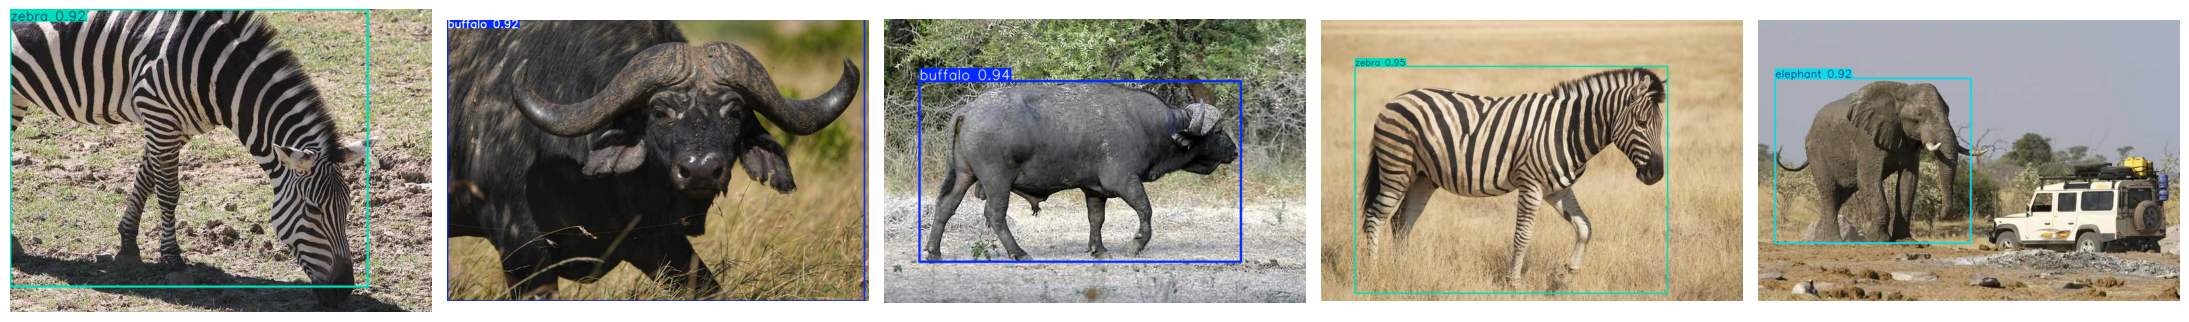

Ошибка #1 (1 (154).jpg): Истина (GT) = [buffalo] | Предсказание = [buffalo, buffalo]
Ошибка #2 (1 (192).jpg): Истина (GT) = [buffalo, buffalo, buffalo] | Предсказание = [buffalo, buffalo, buffalo, buffalo]
Ошибка #3 (1 (317).jpg): Истина (GT) = [buffalo] | Предсказание = [buffalo, buffalo]


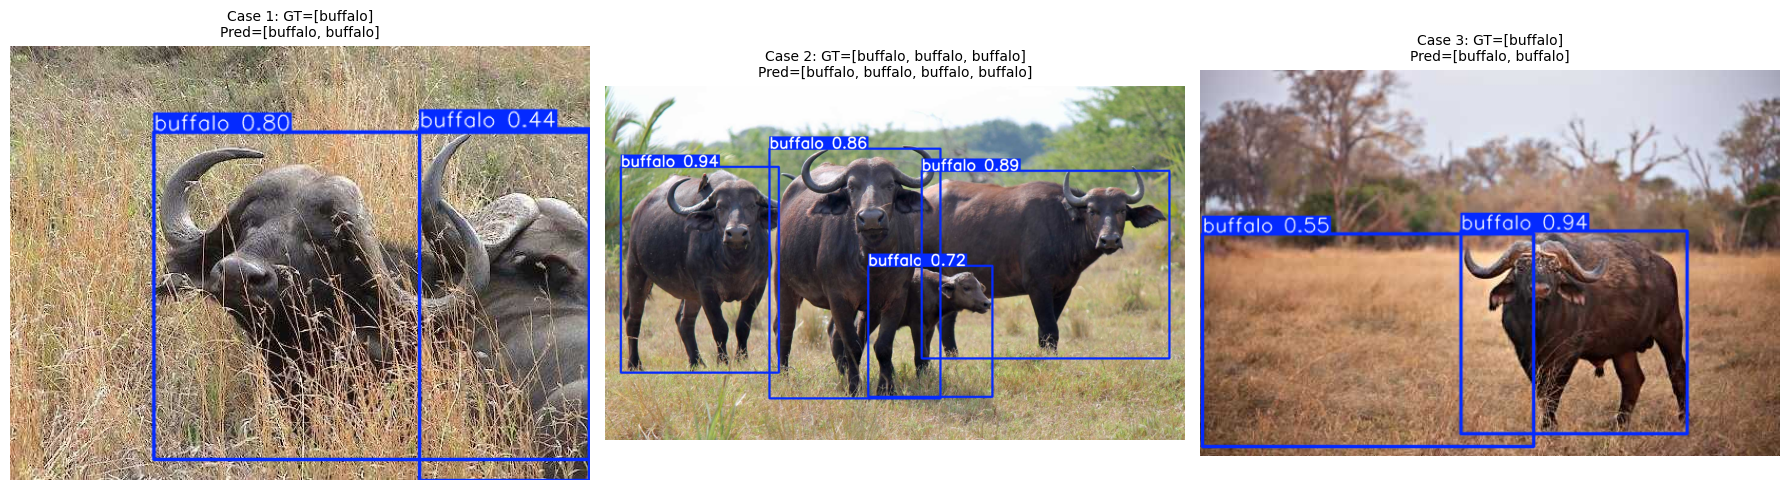


Готово! Архив project_artifacts.zip со всеми графиками и весами создан.


In [5]:
import random
import shutil
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

exp_dir = Path("/content/runs/detect/runs_exp/exp_imgsz384")
base_dir = Path("/content/runs/detect/runs/detect/baseline_256")
best_model = YOLO(str(exp_dir / "weights" / "best.pt"))

# 1. Финальная оценка выбранной модели на отложенном TEST сплите
test_metrics = best_model.val(data="data.yaml", split="test", imgsz=384, conf=0.25, iou=0.50)

print("\n=== ФИНАЛЬНЫЕ РЕЗУЛЬТАТЫ НА TEST (conf=0.25, IoU=0.50) ===")
print(f"Precision (P): {test_metrics.box.mp:.4f}")
print(f"Recall (R):    {test_metrics.box.mr:.4f}")
print(f"mAP@0.50:      {test_metrics.box.map50:.4f}")

# 2. Сохраняем 5 тестовых изображений с предсказаниями (рамка + класс + confidence)
test_imgs = sorted(list(Path("datasets/african-wildlife/african-wildlife/images/test").glob("*.*")))
random.seed(42)
sample_test = random.sample(test_imgs, 5)

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, img_path in zip(axes, sample_test):
    res = best_model.predict(str(img_path), imgsz=384, conf=0.25, iou=0.50, verbose=False)[0]
    plotted = cv2.cvtColor(res.plot(), cv2.COLOR_BGR2RGB)
    ax.imshow(plotted)
    ax.axis("off")
plt.tight_layout()
plt.savefig("test_predictions_5.png", dpi=150)
plt.show()

# 3. Ищем 3 реальные ошибки модели на тесте (несовпадение числа объектов или классов)
class_names = {0: "buffalo", 1: "elephant", 2: "rhino", 3: "zebra"}
failures = []

for img_path in test_imgs:
    lbl_path = Path("datasets/african-wildlife/african-wildlife/labels/test") / f"{img_path.stem}.txt"
    gt_classes = [int(line.split()[0]) for line in lbl_path.read_text().splitlines() if line.strip()]

    res = best_model.predict(str(img_path), imgsz=384, conf=0.25, iou=0.50, verbose=False)[0]
    pred_classes = [int(c) for c in res.boxes.cls.tolist()]

    if sorted(gt_classes) != sorted(pred_classes):
        failures.append((img_path, gt_classes, pred_classes, res))
    if len(failures) == 3:
        break

fig, axes = plt.subplots(1, len(failures), figsize=(18, 5))
if len(failures) == 1:
    axes = [axes]
for idx, (ax, (img_path, gt_c, pr_c, res)) in enumerate(zip(axes, failures), 1):
    gt_str = ", ".join(class_names[c] for c in gt_c) or "none"
    pr_str = ", ".join(class_names[c] for c in pr_c) or "none"
    print(f"Ошибка #{idx} ({img_path.name}): Истина (GT) = [{gt_str}] | Предсказание = [{pr_str}]")
    plotted = cv2.cvtColor(res.plot(), cv2.COLOR_BGR2RGB)
    ax.imshow(plotted)
    ax.set_title(f"Case {idx}: GT=[{gt_str}]\nPred=[{pr_str}]", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.savefig("failure_cases_3.png", dpi=150)
plt.show()

# 4. Собираем все артефакты (графики и финальные веса) в одну папку project_artifacts для скачивания
art = Path("project_artifacts")
art.mkdir(exist_ok=True)
shutil.copy(base_dir / "results.png", art / "baseline_results.png")
shutil.copy(exp_dir / "results.png", art / "experiment_results.png")
shutil.copy(exp_dir / "weights" / "best.pt", art / "best_exp_imgsz384.pt")
for f_name in ["ground_truth_samples.png", "test_predictions_5.png", "failure_cases_3.png"]:
    if Path(f_name).exists():
        shutil.copy(f_name, art / f_name)

shutil.make_archive("project_artifacts", "zip", "project_artifacts")
print("\nГотово! Архив project_artifacts.zip со всеми графиками и весами создан.")